In [1]:
library(ggplot2)
library(ggrepel)
library(data.table)
library(dplyr)
library(rlang)


Attaching package: ‘dplyr’


The following objects are masked from ‘package:data.table’:

    between, first, last


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘rlang’


The following object is masked from ‘package:data.table’:

    :=




In [ ]:
setwd("./real_data_EAS")

In [3]:
data_summary_exp = read.csv("./raw_data/BBJ/EUR_BBJ_exposure_description.csv")
data_summary_exp$UKB.code = as.character(data_summary_exp$UKB.code)

data_summary_out = read.csv("./raw_data/BBJ/EUR_BBJ_outcome_description.csv")
data_summary_out$UKB.phecode = as.character(data_summary_out$UKB.phecode)

In [4]:
code_to_exp = setNames(data_summary_exp$UKB.Phenotype, data_summary_exp$UKB.code)
code_to_out = setNames(data_summary_out$UKB.Phenotype, data_summary_out$UKB.phecode)

### arrange results

In [5]:
# Helper function
load_and_rename <- function(file, cols, suffix, select_cols = c('exposure','outcome','Threshold','nIV','beta','beta.se','beta.pvalue')) {
    df <- fread(file)
    colnames(df) <- cols
    # Special processing for certain columns
    if ("stat" %in% cols) df$beta.se <- abs(df$beta / sqrt(-df$stat))
    if ("pi0" %in% cols)  df$nvalid <- df$nIV * df$pi0
    if (all(c("CL","CU") %in% cols)) df$beta.se <- (df$CU - df$CL) / (2 * qnorm(1 - 0.05 / 2))
    
    df <- as.data.frame(df)[, select_cols, drop = FALSE]
    colnames(df)[3:ncol(df)] <- paste0(colnames(df)[3:ncol(df)], "_", suffix)
    return(df)
}

# Main pipeline: dataset = "TPMI" / "BBJ" / "EUR"
build_merged <- function(dataset = "TPMI", has_xmr = TRUE) {
    dir <- paste0("./", dataset, "_results/")
    
    df_list <- list()
    
    # --- XMR ---
    if (has_xmr) {
        df_xmr <- fread(paste0(dir, "XMR.MRres"))
        df0 <- as.data.frame(df_xmr)[, c('exposure','outcome','exp_N1','exp_N2','Threshold','nIV','nvalid','beta','beta.se','beta.pvalue')]
        colnames(df0)[5:10] <- paste0(colnames(df0)[5:10], "_XMR")
        df_list[["XMR"]] <- df0
    }
    
    # --- TEMR ---
    df_list[["TEMR"]] <- load_and_rename(
        paste0(dir, "TEMR.MRres"),
        cols = c("exposure","outcome","beta","beta.pvalue","stat","nIV","Threshold"),
        suffix = "TEMR"
    )
    
    # --- MRAPSS ---
    df_list[["MRAPSS"]] <- load_and_rename(
        paste0(dir, "MRAPSS.MRres"),
        cols = c("exposure","outcome","beta","beta.se","beta.pvalue","tau.sq","nIV","pi0","IVsignal.sum","Threshold"),
        suffix = "MRAPSS",
        select_cols = c('exposure','outcome','Threshold','nIV','nvalid','beta','beta.se','beta.pvalue')
    )
    
    # --- Standard 7-column methods ---
    std7 <- list(
        IVW       = "IVW.MRres",
        Egger     = "Egger.MRres",
        `Weighted-mode`   = "Weightmode.MRres",
        `Weighted-median`  = "Weightmed.MRres"
    )
    std7_cols <- c('exposure','outcome','beta','beta.se','beta.pvalue','nIV','Threshold')
    
    for (method in names(std7)) {
        df_list[[method]] <- load_and_rename(
            paste0(dir, std7[[method]]),
            cols = std7_cols,
            suffix = method
        )
    }
    
    # --- Standard 8-column methods ---
    std8 <- list(
        IVW_fe     = "IVW_fe.MRres",
        MRMix      = "MRMix.MRres",
        `MR-Robust`  = "MR-Robust.MRres",
        `MR-Lasso`   = "MR-Lasso.MRres",
        `cML-MA`     = "cML-MA.MRres",
        `MR-PRESSO`  = "MR-PRESSO.MRres",
        dIVW       = "dIVW.MRres"
    )
    std8_cols <- c("exposure","outcome","method","Threshold","nIV","beta","beta.se","beta.pvalue")
    
    for (method in names(std8)) {
        df_list[[method]] <- load_and_rename(
            paste0(dir, std8[[method]]),
            cols = std8_cols,
            suffix = method
        )
    }
    
    # --- CAUSE ---
    df_list[["CAUSE"]] <- load_and_rename(
        paste0(dir, "CAUSE.MRres"),
        cols = c('exposure','outcome','beta.pvalue','Threshold','nIV','beta','beta.se','method'),
        suffix = "CAUSE"
    )
    
    # --- ConMix ---
    df_list[["ConMix"]] <- load_and_rename(
        paste0(dir, "ConMix.MRres"),
        cols = c('exposure','outcome','method','Threshold','nIV','beta','beta.pvalue','CL','CU'),
        suffix = "ConMix",
        select_cols = c('exposure','outcome','Threshold','nIV','beta','beta.se','beta.pvalue','CL','CU')
    )
    
    # --- Merge all data frames ---
    df_all <- Reduce(function(x, y) merge(x, y, all = TRUE), df_list)
    
    write.csv(df_all, paste0(dir, dataset, ".csv"), row.names = FALSE)
    return(df_all)
}

##############################
# Run
##############################
df_all_TPMI <- build_merged("TPMI", has_xmr = TRUE)
df_all_BBJ  <- build_merged("BBJ",  has_xmr = TRUE)
df_all_EUR  <- build_merged("EUR",  has_xmr = FALSE)

### START

In [6]:
df_2eas = merge(df_all_TPMI, df_all_BBJ, by=c('exposure','outcome'), suffix=c('_TPMI','_BBJ'))
df_2eas$exposure = as.character(df_2eas$exposure)
df_2eas$outcome = as.character(df_2eas$outcome)
dim(df_2eas)

df_bbj_eur = merge(df_all_EUR, df_all_BBJ, by=c('exposure','outcome'), suffix=c('_EUR','_BBJ'))
df_bbj_eur$exposure = as.character(df_bbj_eur$exposure)
df_bbj_eur$outcome = as.character(df_bbj_eur$outcome)

dim(df_bbj_eur)

[1] 105 174

[1] 105 166

In [7]:
df_2eas$exposure_name = code_to_exp[df_2eas$exposure]
df_2eas$outcome_name = code_to_out[df_2eas$outcome]

df_bbj_eur$exposure_name = code_to_exp[df_bbj_eur$exposure]
df_bbj_eur$outcome_name = code_to_out[df_bbj_eur$outcome]

### Fig. 5A

In [8]:
library(patchwork)

plot_block <- function(df, beta_bbj, beta_eur, pval_bbj, pval_eur, se_bbj, se_eur, method_name, group_cat='no_FDR', plot=FALSE){
    
    df = df[,c('exposure_name', 'outcome_name',beta_bbj, beta_eur, pval_bbj, pval_eur, se_bbj, se_eur)]
    colnames(df) = c('exposure_name', 'outcome_name','beta.x', 'beta.y', 'pval.x', 'pval.y', 'se.x', 'se.y')
    
    max_y = 15
    
    if(sum(df$pval.x < 10^(-max_y), na.rm = TRUE) > 0){
        df[df$pval.x < 10^(-max_y) & !is.na(df$pval.x),]$pval.x = 10^(-max_y)
    }
    df$qval.x <- p.adjust(df$pval.x, method = "BH")
    df$FDR_significant.x <- ifelse(is.na(df$qval.x), NA, df$qval.x < 0.05)
    

    if(sum(df$pval.y < 10^(-max_y), na.rm = TRUE) > 0){
        df[df$pval.y < 10^(-max_y) & !is.na(df$pval.y),]$pval.y = 10^(-max_y)
    }
    df$qval.y <- p.adjust(df$pval.y, method = "BH")
    df$FDR_significant.y <- ifelse(is.na(df$qval.y), NA, df$qval.y < 0.05)
    
    
     df_vis2 <- df %>%
      mutate(
        marker = case_when(
          pval.x < 0.05 & FDR_significant.x ~ "**",   # significant after BH correction -> double *
          pval.x < 0.05 ~ "*",                     # only p-value significant -> single *
          TRUE ~ ""                                     # other cases -> no marker
        )
      )
    
    #############################
    exp_ab_order = c('BMI',
                      'Hb',
                      'ALT',
                      'Glc','HbA1c','LDLC',
                      'DBP')

    out_ab_order = c('PC','BC','UF','IDA',
                      'T2D','GS','Epi','Cat',
                      'AP','UAP','MI','PAD', 
                      'COPD','Asthma',
                      'RA')

    exp_name_to_abbr = setNames(exp_ab_order,

                                c('Body mass index (BMI)', 
                                  'Hemoglobin (Hb)', 
                                  'Alanine aminotransferase (ALT)',
                                  'Glucose (BS)', 'HbA1c (HbA1c)', 'LDL-cholesterol (LDL-C)',
                                  'Diastolic blood pressure (DBP)'))


    out_name_to_abbr = setNames(out_ab_order,

                                c('Prostate cancer', 'Breast cancer', 'Uterine fibroid', 'Iron deficiency anemia', 

                                  'Type 2 diabetes', 'Cholelithiasis', 'Epilepsy', 'Cataract',

                                  'Angina pectoris','Unstable angina pectoris', 'Myocardial infarction', 'Peripheral arterial disease',

                                  'Chronic obstructive pulmonary disease', 'Asthma',

                                  'Rheumatoid arthritis'))



    df_vis2$exp_abbr = exp_name_to_abbr[df_vis2$exposure_name]
    df_vis2$out_abbr = out_name_to_abbr[df_vis2$outcome_name]

    
    df_vis2$exp_abbr <- factor(df_vis2$exp_abbr, levels = exp_ab_order)
    df_vis2$out_abbr <- factor(df_vis2$out_abbr, levels = out_ab_order)

    # NA: grey cell
    df_vis2 <- df_vis2 %>%
        mutate(
            fill_value = ifelse(is.na(beta.x), "NA", beta.x),  # if beta.x is NA，fill in "NA"
            fill_color = ifelse(is.na(beta.x), "grey", beta.x)  # grey: NA
        )


    p <- ggplot(df_vis2, aes(x = exp_abbr, y = out_abbr, fill = beta.x)) +
      geom_tile(color = "white", size = 0.3) +  
      geom_text(aes(label = ifelse(is.na(fill_value), "/", marker)), color = "black", size = 7) +  #  * or ** marker
      scale_fill_gradient2(low = "blue", high = "red", mid = "white", midpoint = 0,
                           limits = c(quantile(df_vis2$beta.x, 0.001, na.rm=TRUE), quantile(df_vis2$beta.x, 0.995, na.rm=TRUE)),  
                           oob = scales::squish) + 
      theme_minimal() +
      labs(
        title = paste0("Causal effects in BBJ with ", method_name), 
        x = "Exposure",
        y = "Outcome",
        fill = expression(beta)
      ) +
      guides(
        fill = guide_colorbar(
          title = expression(beta), 
          barwidth = 3,     
          barheight = 12       
        )
      )


    p = p + theme(plot.title = element_text(size = 28, hjust = 0.5),  
                  axis.text.x = element_text(angle = 20, hjust = 1, size = 16),  
                  axis.text.y = element_text(size = 16),  
                  axis.title.x = element_text(size = 18, face = "bold"),  
                  axis.title.y = element_text(size = 18, face = "bold"),  
                  legend.title = element_text(size = 18, margin = margin(b = 20)),  
                  legend.text = element_text(size = 14),  
                  panel.grid = element_blank()  
                  )


    legend_text <- ggplot() +
      theme_void() +  
      annotate(
        "text", x = 0.5, y = 0.5,
        label = paste("* : P < 0.05", "       ** : Significant after BH correction"),
        hjust = 0.5, size = 5, fontface = "italic"
      ) +
      theme(
        plot.margin = margin(t = 0, r = 0, b = 8, l = 0),
        plot.background = element_rect(fill = "white", color = NA)  
      )
    
    p <- p / legend_text +
          plot_layout(heights = c(10, 1)) 
    
    if(plot) print(p)

    dir.create('./plots/BBJ_block', recursive = TRUE, showWarnings = FALSE)
    ggsave(paste0('./plots/BBJ_block/',method_name,'_',group_cat,'.png'), plot = p, width = 20, height = 16, bg='white')


}

#### save figures in ./plots/BBJ_block/

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


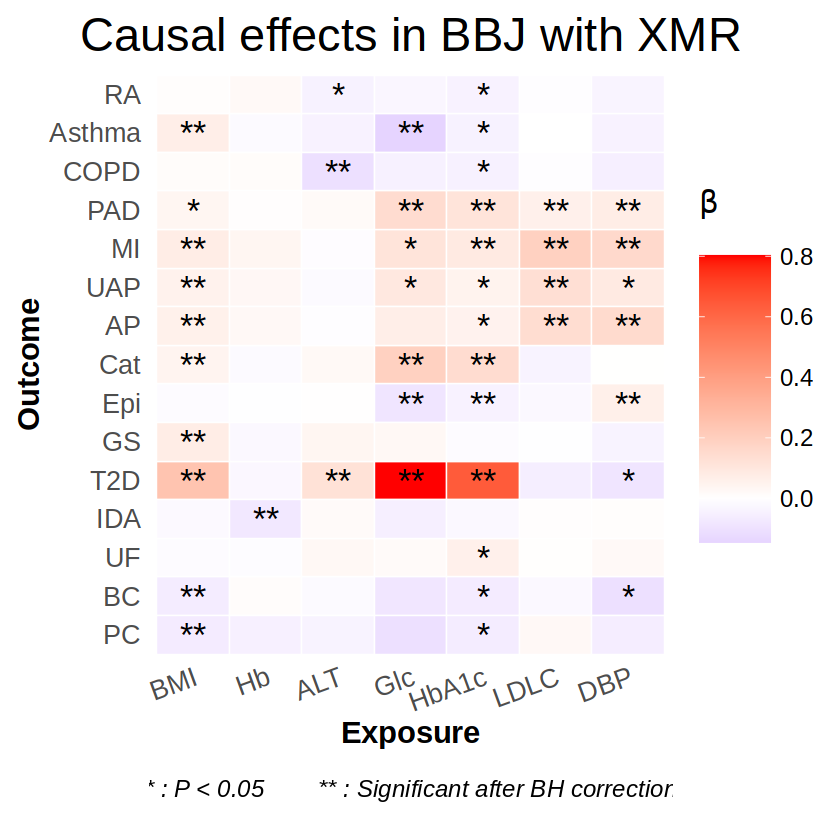

In [9]:
method_list = c('XMR', 'TEMR', 'MRAPSS',
                'Egger', 'Weighted-mode', 'IVW', 'Weighted-median', 
                'CAUSE', 'MRMix', 'MR-Robust', 'MR-PRESSO', 'IVW_fe', 'cML-MA', 'ConMix', 'dIVW', 'MR-Lasso')

method_name_list = method_list

i = 1
method = method_list[i]
method_name = method_name_list[i]

for(group_cat in c('no_FDR')){

    plot_block(df_bbj_eur,
               beta_bbj=paste0('beta_',method), beta_eur=paste0('beta_MRAPSS_EUR'),
               pval_bbj=paste0('beta.pvalue_',method), pval_eur=paste0('beta.pvalue_MRAPSS_EUR'),
               se_bbj=paste0('beta.se_',method), se_eur=paste0('beta.se_MRAPSS_EUR'),
               method_name=method_name, group_cat=group_cat, plot=TRUE)

}


for(i in 2:length(method_list)){
    
    method = method_list[i]
    method_name = method_name_list[i]
    
    for(group_cat in c('no_FDR')){
        
        plot_block(df_bbj_eur,
                   beta_bbj=paste0('beta_',method,'_BBJ'), beta_eur=paste0('beta_',method,'_EUR'),
                   pval_bbj=paste0('beta.pvalue_',method,'_BBJ'), pval_eur=paste0('beta.pvalue_',method,'_EUR'),
                   se_bbj=paste0('beta.se_',method,'_BBJ'), se_eur=paste0('beta.se_',method,'_EUR'),
                   method_name=method_name, group_cat=group_cat)    
        
    }
    
}

### Fig. 5B

In [10]:
sig_num_vec = NULL
sig_num_vec_FDR = NULL

sig_diff_num_vec = NULL
sig_diff_num_vec_FDR = NULL

df_bbj_eur_copy = df_bbj_eur

method_list = c('XMR', 'TEMR', 'MRAPSS',
                'Egger', 'Weighted-mode', 'IVW', 'Weighted-median', 
                'CAUSE', 'MRMix', 'MR-Robust', 'MR-PRESSO', 'IVW_fe', 'cML-MA', 'ConMix', 'dIVW', 'MR-Lasso')

method_name_list = method_list


for(i in 1:length(method_list)){
    
    method = method_list[i]
    method_name = method_name_list[i]
    
    if(method != 'XMR'){
        beta_bbj=paste0('beta_',method,'_BBJ')
        beta_eur=paste0('beta_',method,'_EUR')

        pval_bbj=paste0('beta.pvalue_',method,'_BBJ')
        pval_eur=paste0('beta.pvalue_',method,'_EUR')
        
        se_bbj=paste0('beta.se_',method,'_BBJ')
        se_eur=paste0('beta.se_',method,'_EUR')
        
    }else{
        
        beta_bbj=paste0('beta_XMR')
        beta_eur=paste0('beta_MRAPSS_EUR')

        pval_bbj=paste0('beta.pvalue_XMR')
        pval_eur=paste0('beta.pvalue_MRAPSS_EUR')
        
        se_bbj=paste0('beta.se_XMR')
        se_eur=paste0('beta.se_MRAPSS_EUR')
        
    }

    df = df_bbj_eur_copy
    
    df = df[,c(beta_bbj, beta_eur, pval_bbj, pval_eur, se_bbj, se_eur)]
    colnames(df) = c('beta.x', 'beta.y', 'pval.x', 'pval.y', 'se.x', 'se.y')
    
    max_y = 15
    
    if(sum(df$pval.x < 10^(-max_y), na.rm=TRUE) > 0){
        df[!is.na(df$pval.x) & df$pval.x < 10^(-max_y),]$pval.x = 10^(-max_y)
    }
    df$qval.x <- p.adjust(df$pval.x, method = "BH")

    df$FDR_significant.x <- df$qval.x < 0.05
    
    
    if(sum(df$pval.y < 10^(-max_y), na.rm=TRUE) > 0){
        df[!is.na(df$pval.y) & df$pval.y < 10^(-max_y),]$pval.y = 10^(-max_y)
    }
    df$qval.y <- p.adjust(df$pval.y, method = "BH")

    df$FDR_significant.y <- df$qval.y < 0.05
   
    inds = !is.na(df$FDR_significant.x & df$FDR_significant.y) & (df$FDR_significant.x & df$FDR_significant.y)
    
    sig_num_vec = c(sig_num_vec, sum(df$pval.x < 0.05, na.rm=TRUE))
    sig_num_vec_FDR = c(sig_num_vec_FDR, sum(df$FDR_significant.x, na.rm=TRUE))
    
}

names(sig_num_vec) = method_name_list
names(sig_num_vec_FDR) = method_name_list

sig_num_vec
sig_num_vec_FDR

XMR            TEMR          MRAPSS           Egger   Weighted-mode 
             45              94              26              12              13 
            IVW Weighted-median           CAUSE           MRMix       MR-Robust 
             29              24               7              21              33 
      MR-PRESSO          IVW_fe          cML-MA          ConMix            dIVW 
             30              46              44              36              30 
       MR-Lasso 
             36

XMR            TEMR          MRAPSS           Egger   Weighted-mode 
             30              94              15               0               4 
            IVW Weighted-median           CAUSE           MRMix       MR-Robust 
             16              13               1              11              20 
      MR-PRESSO          IVW_fe          cML-MA          ConMix            dIVW 
             20              38              38              21              16 
       MR-Lasso 
             24

Warning message:
“The `size` argument of `element_rect()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.”


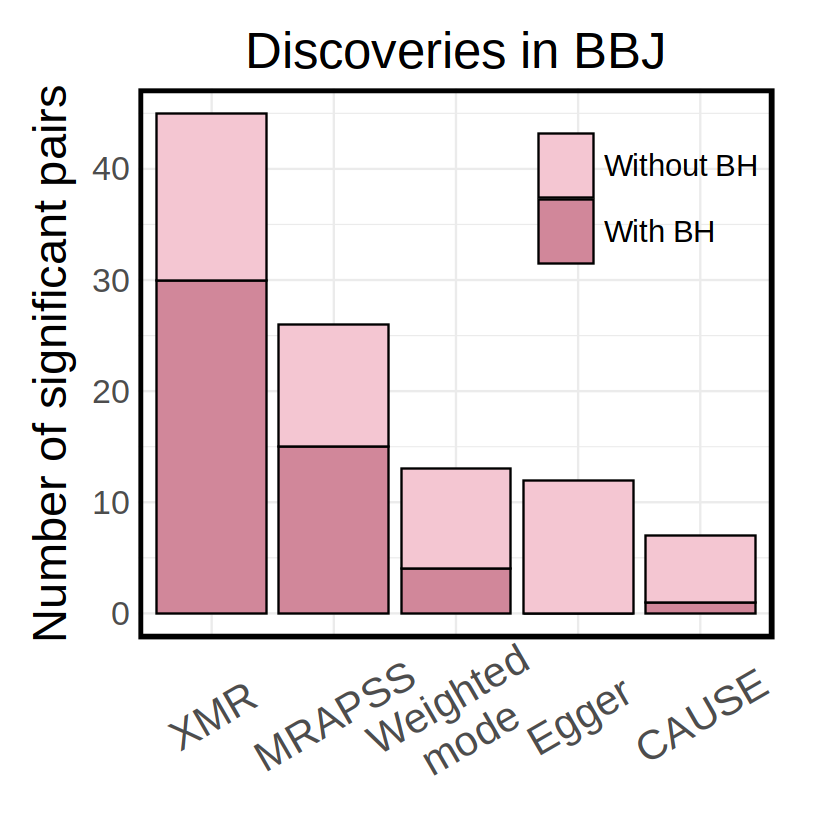

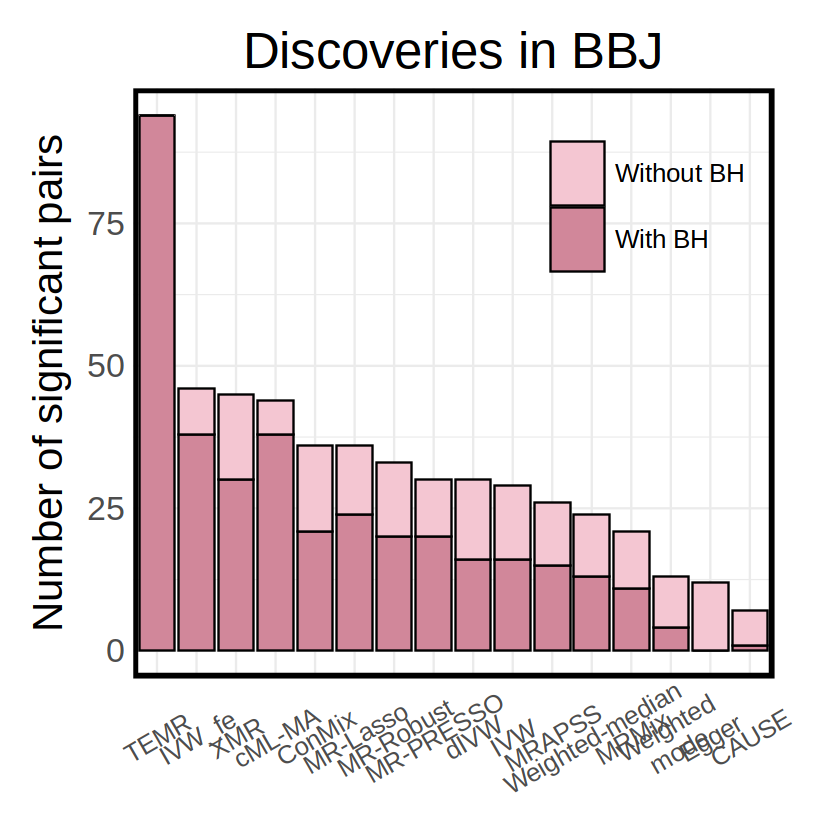

In [11]:
library(scales)

plot_sig_bar <- function(sig_num_vec, sig_num_vec_FDR,
                         title = "Discoveries",
                         part_list = NULL,        # NULL = use all methods
                         rename_map = c("Weighted-mode" = "Weighted\nmode"),
                         filename, width = 16.5, height = 12,
                         x_size = 15, legend_size = 15, y_title_size = 25) {

  df_sig <- data.frame(
    Method      = names(sig_num_vec),
    Total       = sig_num_vec,
    `With BH`   = sig_num_vec_FDR,
    `Without BH`= sig_num_vec - sig_num_vec_FDR,
    check.names = FALSE
  )

  # Subset methods if specified

if (!is.null(part_list)) df_sig <- df_sig[df_sig$Method %in% part_list, ]

  # Rename methods if needed
  for (old in names(rename_map)) {
    df_sig$Method[df_sig$Method == old] <- rename_map[[old]]
  }

  df_sig$Method <- factor(df_sig$Method, levels = df_sig$Method[order(-df_sig$Total)])

  df_long <- tidyr::pivot_longer(df_sig, cols = c("With BH", "Without BH"),
                                 names_to = "Type", values_to = "Count")
  df_long$Type <- factor(df_long$Type, levels = c("Without BH", "With BH"))

  p <- ggplot(df_long, aes(x = Method, y = Count, fill = Type)) +
    geom_bar(stat = "identity", position = "stack", width = 0.9, color = "black") +
    scale_fill_manual(values = c("With BH" = "#d1879a", "Without BH" = "#f4c6d2")) +
    labs(title = title, y = "Number of significant pairs") +
    theme_minimal() +
    theme(
      axis.text.x    = element_text(angle = 30, hjust = 0.5, vjust = 0.58, size = x_size, margin = margin(t = 150)),
      axis.text.y    = element_text(size = 20, margin = margin(r = 15)),
      axis.title.x   = element_blank(),
      axis.title.y   = element_text(size = y_title_size, margin = margin(r = 10)),
      plot.title      = element_text(size = 30, hjust = 0.5),
      legend.position = c(0.8, 0.8),
      legend.key.height = unit(1.4, "cm"),
      legend.key.width  = unit(1.2, "cm"),
      legend.text     = element_text(size = legend_size),
      legend.title    = element_blank(),
      plot.margin     = margin(t = 20, r = 40, b = 20, l = 20),
      panel.border    = element_rect(color = "black", fill = NA, size = 2)
    )

  print(p)
  dir.create(dirname(filename), recursive = TRUE, showWarnings = FALSE)
  ggsave(filename, plot = p, width = width, height = height, bg = "white")
}

# --- Subset version ---
plot_sig_bar(sig_num_vec, sig_num_vec_FDR,
             title = "Discoveries in BBJ",
             part_list = c("XMR", "MRAPSS", "Egger", "Weighted-mode", "CAUSE"),
             filename = "./plots/sig_num_BBJ105_part.png",
             width = 14, x_size = 25, legend_size = 18, y_title_size = 28)

# --- Full version ---
plot_sig_bar(sig_num_vec, sig_num_vec_FDR,
             title = "Discoveries in BBJ",
             filename = "./plots/sig_num_BBJ105.png")

### Fig. 5C

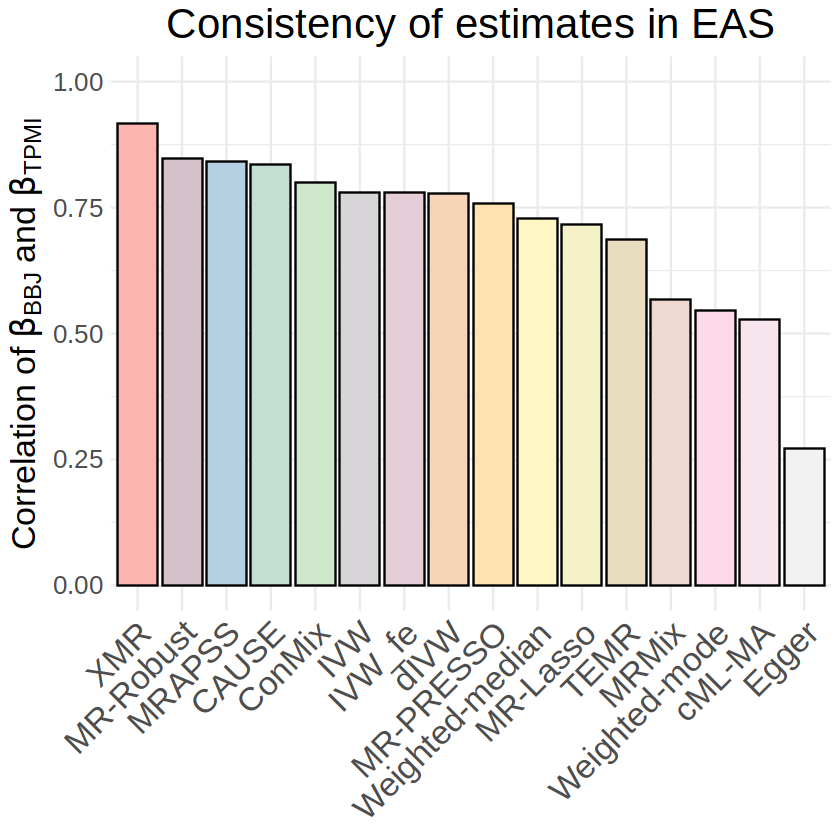

In [12]:
library(RColorBrewer)

cor_vec = NULL

method_list = c('XMR', 'TEMR', 'MRAPSS',
                'Egger', 'Weighted-mode', 'IVW', 'Weighted-median', 
                'CAUSE', 'MRMix', 'MR-Robust', 'MR-PRESSO', 'IVW_fe', 'cML-MA', 'ConMix', 'dIVW', 'MR-Lasso')

method_name_list = method_list

for(i in 1:length(method_list)){
    
    method = method_list[i]
    method_name = method_name_list[i]
    
    beta_bbj=paste0('beta_',method,'_BBJ')
    beta_tpmi=paste0('beta_',method,'_TPMI')
    
    pval_bbj=paste0('beta.pvalue_',method,'_BBJ')
    pval_tpmi=paste0('beta.pvalue_',method,'_TPMI')
    
    df = df_2eas
    
    df = df[,c(beta_bbj, beta_tpmi, pval_bbj, pval_tpmi)]
    colnames(df) = c('beta.x', 'beta.y', 'pval.x', 'pval.y')
    
    max_y = 15
    
    cor_vec = c(cor_vec, 
                cor(na.omit(df)$beta.x, na.omit(df)$beta.y)) 
    
    
}

names(cor_vec) = method_name_list
colors <- colorRampPalette(brewer.pal(9, "Pastel1"))(length(cor_vec))

cor_vec = round(cor_vec, 3)

df_cor_sig0 <- data.frame(
  method = names(cor_vec),
  cor = as.numeric(round(cor_vec,3))
)

df_cor_sig = df_cor_sig0

df_cor_sig <- df_cor_sig[order(-df_cor_sig$cor), ]  # 按 Value 倒序排列

df_cor_sig$method <- factor(df_cor_sig$method, levels = df_cor_sig$method)


ggplot(df_cor_sig, aes(x = method)) +
  geom_bar(aes(y = cor, fill = method),  
           stat = "identity",  color = "black") +
  scale_y_continuous(
    limits = c(0, 1),
    name = expression("Correlation of "* beta[BBJ] *" and "*beta[TPMI]) 
  ) +
  scale_fill_manual(values = colors) +
  labs(
    title = "Consistency of estimates in EAS",
    x = "Method"
  ) +
  theme_minimal() +
  theme(
    legend.position = "none",
    axis.text.x = element_text(angle = 45, hjust = 1, size = 20),  
    axis.text.y = element_text(size = 15),                        
    axis.title.x = element_blank(),                       
    axis.title.y = element_text(size = 20),          
    plot.title = element_text(size = 25, hjust = 0.5)           
  )

ggsave('./plots/cor_method.png', width = 16, height = 12, bg='white')

### Fig. 5D

In [13]:
plot_comp <- function(df, beta_bbj, beta_tpmi, pval_bbj, pval_tpmi, se_bbj, se_tpmi, method_name, group_cat='no_FDR', plot=FALSE){
    
    df = df[,c(beta_bbj, beta_tpmi, pval_bbj, pval_tpmi, se_bbj, se_tpmi)]
    colnames(df) = c('beta.x', 'beta.y', 'pval.x', 'pval.y', 'se.x', 'se.y')
    
    ###
    df = na.omit(df)
    
    max_y = 15
    
    if(sum(df$pval.x < 10^(-max_y)) > 0){
        df[df$pval.x < 10^(-max_y),]$pval.x = 10^(-max_y)
    }
    df$qval.x <- p.adjust(df$pval.x, method = "BH")

    df$FDR_significant.x <- df$qval.x < 0.05
    
    
    if(sum(df$pval.y < 10^(-max_y)) > 0){
        df[df$pval.y < 10^(-max_y),]$pval.y = 10^(-max_y)
    }
    df$qval.y <- p.adjust(df$pval.y, method = "BH")

    df$FDR_significant.y <- df$qval.y < 0.05


    model <- lm(beta.y ~ beta.x, data = df)
    model_summary <- summary(model)

    r_squared <- round(model_summary$r.squared, 3)
    
    corr = cor(df$beta.x, df$beta.y)
    corr = round(corr, 3)
    
    if(group_cat == 'no_FDR'){
        df$group <- with(df, ifelse(pval.x < 0.05 & pval.y < 0.05, "Both significant",
                                      ifelse(pval.x < 0.05, "Only significant in BBJ",
                                      ifelse(pval.y < 0.05, "Only significant in TPMI", "Neither"))))
    }else if(group_cat == 'FDR'){
        df$group <- with(df, ifelse(FDR_significant.x & FDR_significant.y, "Both significant",
                                      ifelse(FDR_significant.x, "Only significant in BBJ",
                                      ifelse(FDR_significant.y, "Only significant in TPMI", "Neither"))))
    }

    df$group <- factor(df$group, levels = c("Only significant in TPMI", "Only significant in BBJ", "Neither", "Both significant"))

    df <- df[order(df$group), ]

    p = ggplot(df, aes(x = beta.x, y = beta.y, color = group)) +
      geom_point(size = 3., alpha=0.8) + 
      geom_errorbar(data = subset(df, group == "Neither"), 
                    aes(ymin = beta.y - 1.96*se.y, ymax = beta.y + 1.96*se.y), 
                    width = 0.035, size = 0.4, alpha = 0.22) + 
      geom_errorbar(data = subset(df, group != "Neither"), 
                    aes(ymin = beta.y - 1.96*se.y, ymax = beta.y + 1.96*se.y), 
                    width = 0.035, size = 0.4, alpha = 0.45) + 

      geom_errorbarh(data = subset(df, group == "Neither"), 
                     aes(xmin = beta.x - 1.96*se.x, xmax = beta.x + 1.96*se.x), 
                     width = 0.035, size = 0.4, alpha = 0.22) +
      geom_errorbarh(data = subset(df, group != "Neither"), 
                     aes(xmin = beta.x - 1.96*se.x, xmax = beta.x + 1.96*se.x), 
                     width = 0.035, size = 0.4, alpha = 0.45) + 
    
      geom_abline(slope = 1, intercept = 0, linetype = "dashed", color = "grey", size = 1) +  # y=x
      geom_vline(xintercept = 0, linetype = "dashed", color = "gray50", size = 1) +  # x=0
      geom_hline(yintercept = 0, linetype = "dashed", color = "gray50", size = 1) +  # y=0
    
      geom_smooth(method = "lm", color = "red", fill = "pink", level = 0.95) +  # linear regression fit and 95% CI
      annotate("text", x = min(df$beta.x)-0.05, y = max(df$beta.y)-0.05, 
               label = paste("Corr =", corr), hjust = 0, size = 8, color = "black") +  # add R²

      scale_color_manual(values = c("Both significant" = "coral",
                                    "Only significant in BBJ" = "deepskyblue3",
                                    "Only significant in TPMI" = "chartreuse3",
                                    "Neither" = "black")) +  # color setting
      labs(
        title = paste0("Effect size comparison with ", method_name),
        x = "Effect size in BBJ",
        y = "Effect size in TPMI",
        color = "Group"
      ) +
      theme_minimal() + 
      theme(
        plot.title = element_text(size = 25, hjust = 0.4), 
        axis.line.x = element_line(size = 0.85, color = "black"), 
        axis.line.y = element_line(size = 0.85, color = "black"),
        axis.text.x = element_text(size = 20),  
        axis.text.y = element_text(size = 20),  
        axis.title = element_text(size = 20),  
        axis.ticks = element_line(size = 1.8), 
        text = element_text(size = 15),  
        legend.position = c(0.7,0.13),
        legend.key.height = unit(0.8, "cm"),
        legend.key.width = unit(0.8, "cm"),
        legend.text = element_text(size = 15),
        legend.title = element_blank(),
        panel.grid = element_blank()    
      )+
     xlim(min(df$beta.x)-0.05,max(df$beta.x + 1.96*df$se.x)+0.007)
    
    if(plot) print(p)
    
    dir.create('./plots/pair_comp', recursive = TRUE, showWarnings = FALSE)
    ggsave(paste0('./plots/pair_comp/',method_name,'_',group_cat,'.png'), plot = p, width = 13, height = 8.5, bg='white')
}


#### save figures in ./plots/pair_comp/

Warning message:
“`geom_errorbarh()` was deprecated in ggplot2 4.0.0.
ℹ Please use the `orientation` argument of `geom_errorbar()` instead.”
Warning message:
“The `size` argument of `element_line()` is deprecated as of ggplot2 3.4.0.
ℹ Please use the `linewidth` argument instead.”
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x'
`geom_smooth()` using formula = 'y ~ x

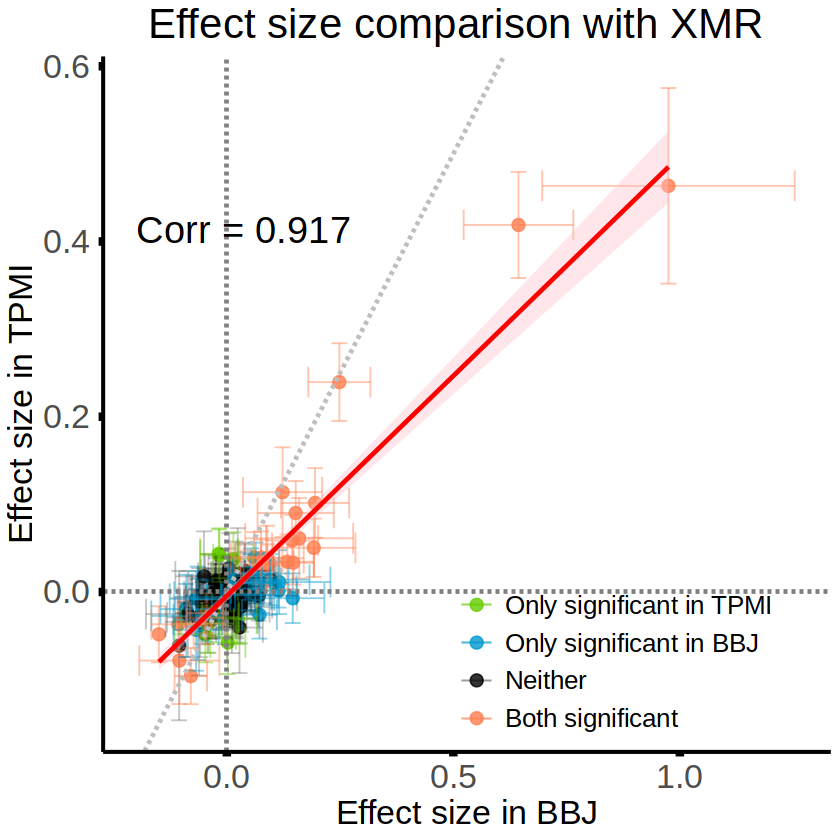

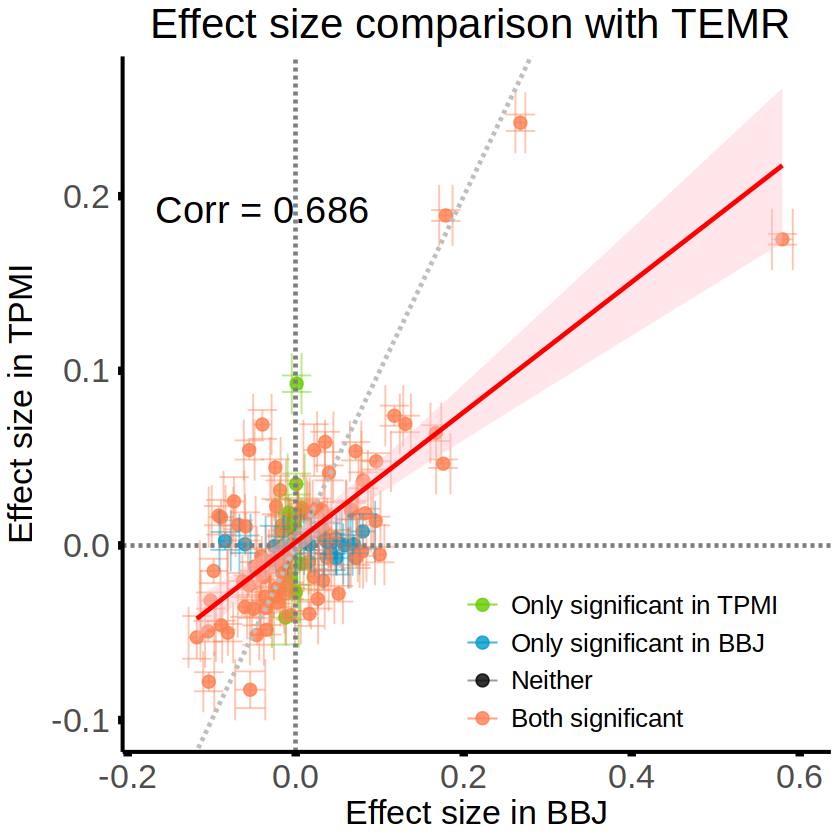

In [14]:
method_list = c('XMR', 'TEMR', 'MRAPSS',
                'Egger', 'Weighted-mode', 'IVW', 'Weighted-median', 
                'CAUSE', 'MRMix', 'MR-Robust', 'MR-PRESSO', 'IVW_fe', 'cML-MA', 'ConMix', 'dIVW', 'MR-Lasso')

method_name_list = method_list

for(i in 1:length(method_list)){
    
    method = method_list[i]
    method_name = method_name_list[i]

    if(method %in% c('XMR', 'TEMR')){
        plot_comp(df_2eas, 
                  beta_bbj=paste0('beta_',method,'_BBJ'), beta_tpmi=paste0('beta_',method,'_TPMI'), 
                  pval_bbj=paste0('beta.pvalue_',method,'_BBJ'), pval_tpmi=paste0('beta.pvalue_',method,'_TPMI'), 
                  se_bbj=paste0('beta.se_',method,'_BBJ'), se_tpmi=paste0('beta.se_',method,'_TPMI'), 
                  method_name=method_name, group_cat='no_FDR', plot=TRUE)
    }else{
        plot_comp(df_2eas, 
                  beta_bbj=paste0('beta_',method,'_BBJ'), beta_tpmi=paste0('beta_',method,'_TPMI'), 
                  pval_bbj=paste0('beta.pvalue_',method,'_BBJ'), pval_tpmi=paste0('beta.pvalue_',method,'_TPMI'), 
                  se_bbj=paste0('beta.se_',method,'_BBJ'), se_tpmi=paste0('beta.se_',method,'_TPMI'), 
                  method_name=method_name, group_cat='no_FDR', plot=FALSE)
    }
}

### Fig. 5F

In [15]:
exp_ab_order = c('BMI','Hb','ALT','Glc','HbA1c','LDLC','DBP')

out_ab_order = c('PC','BC','UF','IDA',
                  'T2D','GS','Epi','Cat',
                  'AP','UAP','MI','PAD', 
                  'COPD','Asthma','RA')

exp_name_to_abbr = setNames(exp_ab_order,
                            c('Body mass index (BMI)', 'Hemoglobin (Hb)',
                              'Alanine aminotransferase (ALT)',
                              'Glucose (BS)', 'HbA1c (HbA1c)', 'LDL-cholesterol (LDL-C)',
                              'Diastolic blood pressure (DBP)'))


out_name_to_abbr = setNames(out_ab_order,
                            c('Prostate cancer', 'Breast cancer', 'Uterine fibroid','Iron deficiency anemia', 
                              'Type 2 diabetes', 'Cholelithiasis', 'Epilepsy', 'Cataract',
                              'Angina pectoris','Unstable angina pectoris', 'Myocardial infarction', 'Peripheral arterial disease',
                              'Chronic obstructive pulmonary disease', 'Asthma','Rheumatoid arthritis'))

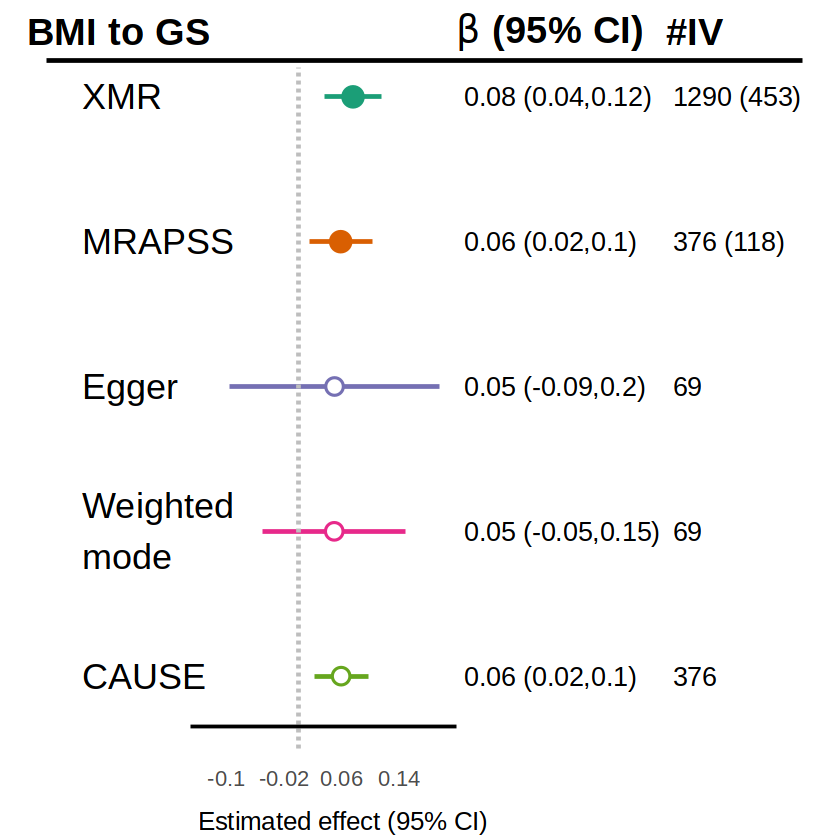

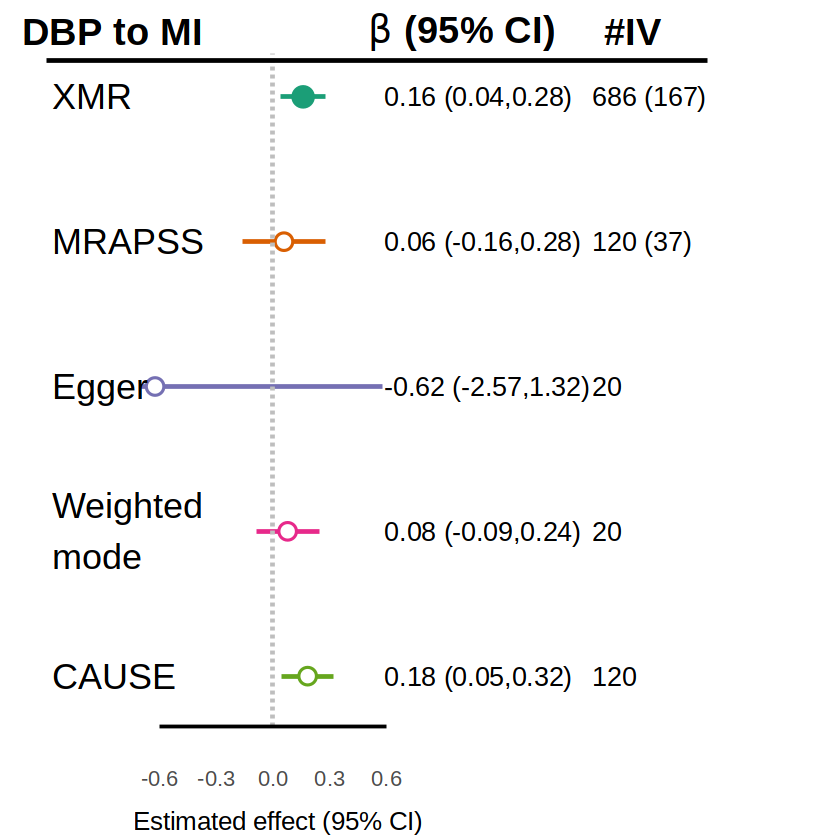

In [16]:
library(scales)
library(RColorBrewer)

# ==== extract MR estimates for one exposure-outcome pair ====
extract_mr_data <- function(df_row, methods) {
  get_col <- function(prefix, m, sfx) df_row[[paste0(prefix, "_", m, sfx)]]

  do.call(rbind, lapply(methods, function(m) {
    is_xmr  <- (m == "XMR")
    eas_sfx <- ifelse(is_xmr, "", "_BBJ")
    data.frame(
      method   = m,
      beta_EAS = get_col("beta",        m, eas_sfx),
      se_EAS   = get_col("beta.se",     m, eas_sfx),
      pval_EAS = get_col("beta.pvalue", m, eas_sfx),
      nIV_EAS  = get_col("nIV",         m, eas_sfx),
      beta_EUR = if (is_xmr) NA else get_col("beta",        m, "_EUR"),
      se_EUR   = if (is_xmr) NA else get_col("beta.se",     m, "_EUR"),
      pval_EUR = if (is_xmr) NA else get_col("beta.pvalue", m, "_EUR"),
      nIV_EUR  = if (is_xmr) NA else get_col("nIV",         m, "_EUR"),
      stringsAsFactors = FALSE
    )
  }))
}

# ==== compute 95% CI and text labels for one population ====
add_ci_and_text <- function(df, pop) {
  b  <- df[[paste0("beta_", pop)]]
  se <- df[[paste0("se_", pop)]]
  lo <- b - 1.96 * se;  up <- b + 1.96 * se

  df[[paste0("Lower_CI_", pop)]]     <- lo
  df[[paste0("Upper_CI_", pop)]]     <- up
  df[[paste0("beta_CI_text_", pop)]] <- paste0(round(b, 2), " (", round(lo, 2), ",", round(up, 2), ")")
  df[[paste0("IV_text_", pop)]]      <- df[[paste0("nIV_", pop)]]
  df[[paste0("sig_", pop)]]          <- as.character(df[[paste0("pval_", pop)]] < 0.05)
  df
}

# ==== append "(valid IV)" counts for XMR (EAS) and MRAPSS (both) ====
annotate_valid_ivs <- function(df2, df_row) {
  fmt <- function(niv, nvalid) paste0(niv, " (", round(nvalid), ")")

  # XMR valid IVs – EAS only
  if ("nvalid_XMR" %in% names(df_row)) {
    i <- which(df2$method == "XMR")
    df2[i, "IV_text_EAS"] <- fmt(df2[i, "nIV_EAS"], df_row[["nvalid_XMR"]])
  }
  # MRAPSS valid IVs – both populations
  for (pop in c("EAS", "EUR")) {
    col <- paste0("nvalid_MRAPSS", ifelse(pop == "EAS", "_BBJ", "_EUR"))
    if (col %in% names(df_row)) {
      i <- which(df2$method == "MRAPSS")
      df2[i, paste0("IV_text_", pop)] <- fmt(df2[i, paste0("nIV_", pop)], df_row[[col]])
    }
  }
  df2
}

# ==== Main forest-plot function ====
plot_forest <- function(df_bbj_eur_copy, exposure, outcome,
                        # x-axis scale
                        xlim, x_breaks, x_labels,
                        # x-positions for the three text columns
                        x_pos = list(method = -0.3, beta_ci = 0.23, iv = 0.52),
                        # x-positions for header labels and line
                        x_hdr = list(title = -0.25, beta = 0.35, iv = 0.55,
                                     line = c(-0.35, 0.7)),
                        # bottom axis-tick segment
                        x_axis_seg = c(-0.15, 0.22),
                        # dashed zero-line y range
                        y_dash = c(0.65, 5.3),
                        # optional CI clipping
                        clip_lower = NULL, clip_upper = NULL,
                        # x-axis title hjust
                        axis_x_hjust = 0.3,
                        # output
                        filename = NULL, width = 14.5, height = 8.6,
                        methods = c("XMR", "Egger", "Weighted-mode", "MRAPSS", "CAUSE")) {

  # --- data preparation ---
  df_row <- df_bbj_eur_copy[df_bbj_eur_copy$exposure == exposure &
                              df_bbj_eur_copy$outcome == outcome, ]

  df2 <- extract_mr_data(df_row, methods)
  for (pop in c("EAS", "EUR")) df2 <- add_ci_and_text(df2, pop)
  df2 <- annotate_valid_ivs(df2, df_row)

  # Clip CIs if requested (keep text labels intact)
  if (!is.null(clip_lower)) df2$Lower_CI_EAS <- pmax(df2$Lower_CI_EAS, clip_lower)
  if (!is.null(clip_upper)) df2$Upper_CI_EAS <- pmin(df2$Upper_CI_EAS, clip_upper)

  # Display-ready method names and factor order
  df2$method <- gsub("Weighted-mode", "Weighted\nmode", df2$method)
  lvls <- c("XMR", "MRAPSS", "Egger", "Weighted\nmode", "CAUSE")
  df2$method <- factor(df2$method, levels = lvls)

  # Colour scheme: filled if significant, white if not
  method_colors <- setNames(brewer.pal(length(lvls), "Dark2"), lvls)
  df2$fill_color <- ifelse(df2$sig_EAS == "TRUE", as.character(df2$method), "FALSE")

  # Header title
  title_label <- paste0(exp_name_to_abbr[code_to_exp[exposure]],
                         " to ",
                         out_name_to_abbr[code_to_out[outcome]])

  # --- build ggplot ---
  p <- ggplot(df2, aes(y = method, x = beta_EAS)) +
    # CI line and point estimate
    geom_linerange(aes(xmin = Lower_CI_EAS, xmax = Upper_CI_EAS, color = method), size = 1) +
    geom_point(aes(shape = sig_EAS, size = sig_EAS, fill = fill_color, color = method), stroke = 1) +

    # Dashed zero reference line (annotate avoids "length 1" warning)
    annotate("segment", x = 0, xend = 0, y = y_dash[1], yend = y_dash[2],
             linetype = "dashed", color = "grey", linewidth = 1) +

    # Scales
    scale_shape_manual(values = c("TRUE" = 21, "FALSE" = 21)) +
    scale_size_manual(values  = c("TRUE" = 4.8, "FALSE" = 4)) +
    scale_color_manual(values = method_colors) +
    scale_fill_manual(values  = c(method_colors, "FALSE" = "white")) +
    scale_y_discrete(limits   = rev(lvls)) +
    scale_x_continuous(limits = xlim, breaks = x_breaks, labels = x_labels) +

    # In-plot text columns: method name, beta (95% CI), #IV
    geom_text(aes(x = x_pos$method,  label = method),           hjust = 0, size = 7.5) +
    geom_text(aes(x = x_pos$beta_ci, label = beta_CI_text_EAS), hjust = 0, size = 5.5) +
    geom_text(aes(x = x_pos$iv,      label = IV_text_EAS),      hjust = 0, size = 5.5) +

    # Header line and column titles (all annotate to avoid warnings)
    annotate("segment", x = x_hdr$line[1], xend = x_hdr$line[2],
             y = 5.25, yend = 5.25, linewidth = 1) +
    annotate("text", x = x_hdr$title, y = 5.45, label = title_label,
             size = 8, fontface = "bold") +
    annotate("text", x = x_hdr$beta,  y = 5.45,
             label = "bold(beta)~bold('(95% CI)')", parse = TRUE, size = 8) +
    annotate("text", x = x_hdr$iv,    y = 5.45, label = "#IV",
             size = 8, fontface = "bold") +

    # Bottom axis tick segment
    annotate("segment", x = x_axis_seg[1], xend = x_axis_seg[2],
             y = 0.65, yend = 0.65, color = "black", linewidth = 0.8) +

    theme_minimal() +
    theme(
      panel.grid      = element_blank(),
      axis.title.y    = element_blank(),
      axis.title.x    = element_text(size = 15, margin = margin(t = 12), hjust = axis_x_hjust),
      axis.text.y     = element_blank(),
      axis.text.x     = element_text(size = 13, margin = margin(t = 5)),
      axis.line.x     = element_blank(),
      axis.ticks.x    = element_blank(),
      plot.margin     = margin(t = 6, r = 0, b = 3, l = 5),
      legend.position = "none"
    ) +
    labs(x = "Estimated effect (95% CI)")

  print(p)

  if (!is.null(filename)) {
    dir.create(dirname(filename), recursive = TRUE, showWarnings = FALSE)
    ggsave(filename, plot = p, width = width, height = height, bg = "white")
  }
  invisible(p)
}

# ===========================================================
#  Generate the two forest plots
# ===========================================================

# Plot 1: BMI → Cholelithiasis
plot_forest(
  df_bbj_eur_copy, exposure = "21001", outcome = "574.1",
  xlim       = c(-0.35, 0.7),
  x_breaks   = seq(-0.1, 0.2, 0.08),
  x_labels   = c("-0.1", "-0.02", "0.06", "0.14"),
  x_pos      = list(method = -0.3,  beta_ci = 0.23, iv = 0.52),
  x_hdr      = list(title = -0.25, beta = 0.35, iv = 0.55, line = c(-0.35, 0.7)),
  x_axis_seg = c(-0.15, 0.22),
  y_dash     = c(0.5, 5.2),
  axis_x_hjust = 0.35,
  filename   = "./plots/BBJ_block/21001_574.1.png"
)

# Plot 2: DBP → Myocardial Infarction
plot_forest(
  df_bbj_eur_copy, exposure = "4079", outcome = "411.2",
  xlim       = c(-1.2, 2.8),
  x_breaks   = seq(-0.6, 0.6, 0.3),
  x_labels   = c("-0.6", "-0.3", "0.0", "0.3", "0.6"),
  x_pos      = list(method = -1.17, beta_ci = 0.59, iv = 1.69),
  x_hdr      = list(title = -0.85, beta = 1.0, iv = 1.9, line = c(-1.2, 2.3)),
  x_axis_seg = c(-0.6, 0.6),
  clip_lower = -0.7, clip_upper = 0.58,
  axis_x_hjust = 0.23,
  filename   = "./plots/BBJ_block/4079_411.2.png"
)

### Fig. 5G, 5H

In [17]:
df_nIV_by_EAS = fread('./BBJ_results/nIV_by_EAS.MRres')
colnames(df_nIV_by_EAS) = c('exposure', 'outcome', 'Threshold', 'nIV')

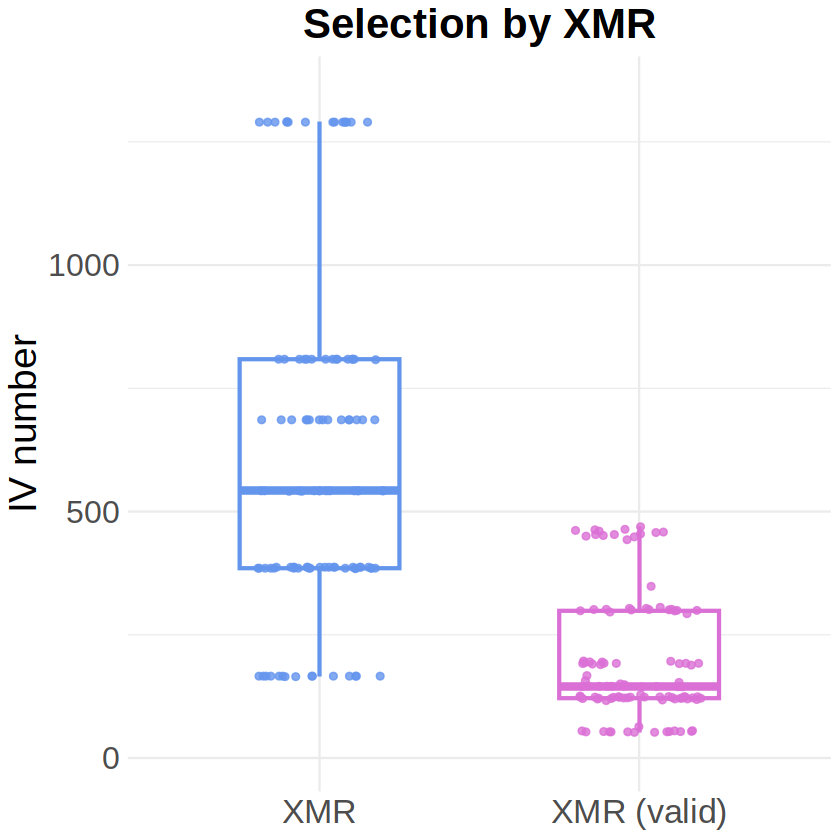

In [18]:
library(tidyr)

# ========================
# Plot G: XMR vs XMR (valid)
# ========================

df_G <- df_all_BBJ %>%
  select(nIV_XMR, nvalid_XMR) %>%
  pivot_longer(cols = everything(),
               names_to = "type", values_to = "IV_number") %>%
  mutate(type = recode(type,
                       "nIV_XMR"    = "XMR",
                       "nvalid_XMR" = "XMR (valid)"))

df_G$type <- factor(df_G$type, levels = c("XMR", "XMR (valid)"))

# Compute shared y-axis range from both datasets
y_max <- max(c(df_G$IV_number, df_nIV_by_EAS$nIV), na.rm = TRUE)
y_range <- c(0, y_max * 1.05)

pG <- ggplot(df_G, aes(x = type, y = IV_number, color = type)) +
  geom_boxplot(outlier.shape = NA, width = 0.5, linewidth = 0.9) +
  geom_jitter(width = 0.2, size = 1.5, alpha = 0.8) +
  scale_color_manual(values = c("XMR" = "cornflowerblue", "XMR (valid)" = "orchid")) +
  scale_y_continuous(limits = y_range) +
  labs(title = "Selection by XMR", x = NULL, y = "IV number") +
  theme_minimal() +
  theme(legend.position = "none",
        plot.title = element_text(hjust = 0.5, size = 25, face = "bold"),
        axis.title.y = element_text(size = 23),
        axis.text.x  = element_text(size = 20),
        axis.text.y  = element_text(size = 19))

pG

ggsave(paste0('./plots/nIV_XMR.png'), plot = pG, width = 13, height = 8.8, bg='white')

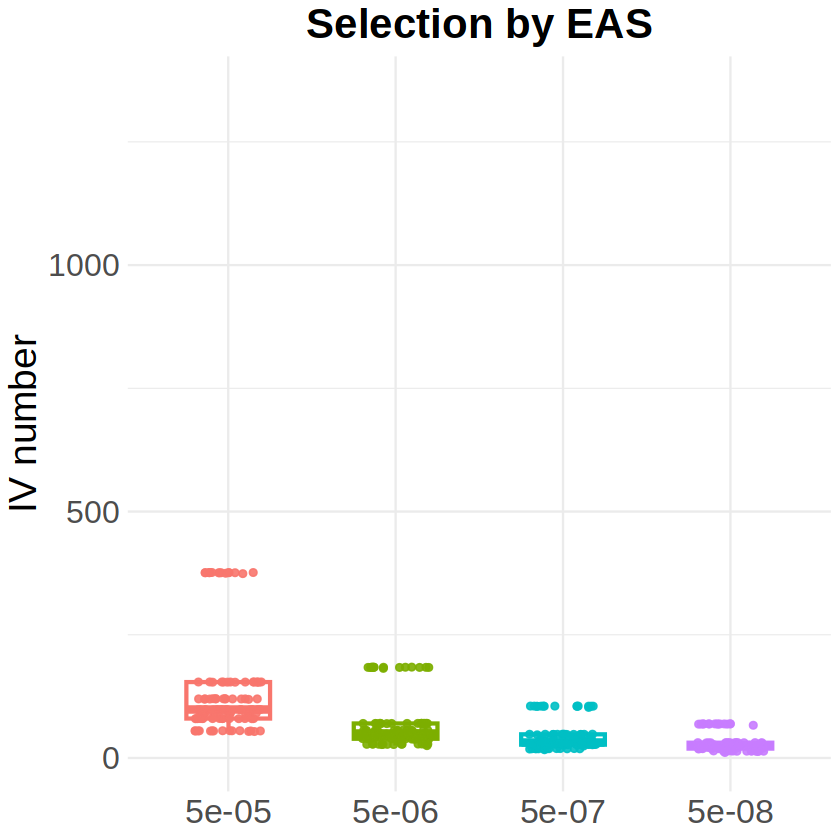

In [19]:
# ========================
# Plot H: Selection by EAS threshold
# ========================

df_nIV_by_EAS$Threshold <- factor(df_nIV_by_EAS$Threshold,
                                   levels = c("5e-05", "5e-06", "5e-07", "5e-08"))

pH <- ggplot(df_nIV_by_EAS, aes(x = Threshold, y = nIV, color = Threshold)) +
  geom_boxplot(outlier.shape = NA, width = 0.5, linewidth = 0.9) +
  geom_jitter(width = 0.2, size = 1.5, alpha = 0.9) +
  scale_y_continuous(limits = y_range) +
  labs(title = "Selection by EAS", x = NULL, y = "IV number") +
  theme_minimal() +
  theme(legend.position = "none",
        plot.title = element_text(hjust = 0.5, size = 25, face = "bold"),
        axis.title.y = element_text(size = 23),
        axis.text.x  = element_text(size = 20),
        axis.text.y  = element_text(size = 19))

pH

ggsave(paste0('./plots/nIV_by_EAS.png'), plot = pH, width = 13, height = 8.8, bg='white')

### Fig. 5E

### meta-analysis between BBJ and TPMI

In [20]:
library(Matrix)

run_tram_for_method <- function(df, method_name) {
  
  cat(sprintf("\n>>> Processing Method: %s <<<\n", method_name))
  
  # 1. Dynamically construct column names
  col_beta_bbj  <- paste0("beta_", method_name, "_BBJ")
  col_beta_tpmi <- paste0("beta_", method_name, "_TPMI")
  col_se_bbj    <- paste0("beta.se_", method_name, "_BBJ")
  col_se_tpmi   <- paste0("beta.se_", method_name, "_TPMI")
  
  # Check whether the required columns exist
  required_cols <- c(col_beta_bbj, col_beta_tpmi, col_se_bbj, col_se_tpmi)
  if (!all(required_cols %in% colnames(df))) {
    return(NULL)
  }
  
  # 2. Extract data matrices
  B_mat_full <- as.matrix(df[, c(col_beta_bbj, col_beta_tpmi)])
  SE_mat_full <- as.matrix(df[, c(col_se_bbj, col_se_tpmi)])
  N_full <- nrow(df)
  
  # ============================================================
  # STEP 1: Estimate Omega (must use complete cases)
  # ============================================================
  # Only rows with non-missing values on both sides can contribute
  # to the cross-population covariance estimation
  valid_idx_for_omega <- complete.cases(B_mat_full, SE_mat_full)
  
  if (sum(valid_idx_for_omega) < 10) {
    warning(paste("Skipping", method_name, "- Too few overlapping rows for Omega estimation."))
    return(NULL)
  }
  
  B_mat_sub <- B_mat_full[valid_idx_for_omega, ]
  SE_mat_sub <- SE_mat_full[valid_idx_for_omega, ]
  N_sub <- nrow(B_mat_sub)
  
  # Method-of-Moments (MoM) estimation of Omega
  sum_beta_outer <- t(B_mat_sub) %*% B_mat_sub
  sum_S_diag <- colSums(SE_mat_sub^2)
  sum_S_mat <- diag(sum_S_diag)
  Omega <- (sum_beta_outer - sum_S_mat) / N_sub
  
  # Floor negative/zero diagonal entries to a small positive value
  if (Omega[1, 1] <= 0) {
    warning(paste(method_name, ": Omega[1,1] (BBJ) is negative/zero. Flooring to 1e-6."))
    Omega[1, 1] <- 1e-6
  }
  if (Omega[2, 2] <= 0) {
    warning(paste(method_name, ": Omega[2,2] (TPMI) is negative/zero. Flooring to 1e-6."))
    Omega[2, 2] <- 1e-6
  }

  # Ensure the off-diagonal element does not violate positive-definiteness
  # Correlation = Cov / sqrt(Var1 * Var2)
  # If |Cov| > sqrt(Var1 * Var2), clip Cov to the feasible range
  max_cov <- sqrt(Omega[1, 1] * Omega[2, 2]) * 0.999 # multiply by 0.999 to guard against numerical issues
  if (abs(Omega[1, 2]) > max_cov) {
    warning(paste(method_name, ": Covariance too large. Clipping to feasible range."))
    sign_cov <- sign(Omega[1, 2])
    Omega[1, 2] <- sign_cov * max_cov
    Omega[2, 1] <- sign_cov * max_cov
  }

  cat("Estimated Omega:\n")
  print(Omega)

  
  # Pre-compute matrix parameters
  omega11 <- Omega[1, 1]; omega22 <- Omega[2, 2]
  omega1 <- Omega[, 1, drop = FALSE]; omega2 <- Omega[, 2, drop = FALSE]
  
  M1 <- Omega - (omega1 %*% t(omega1)) / omega11
  vec1 <- omega1 / omega11
  
  M2 <- Omega - (omega2 %*% t(omega2)) / omega22
  vec2 <- omega2 / omega22
  
  # ============================================================
  # STEP 2: Row-wise TRAM computation (with fallback/downgrade logic)
  # ============================================================
  
  beta_TRAM_1 <- rep(NA, N_full)
  var_TRAM_1 <- rep(NA, N_full)
  beta_TRAM_2 <- rep(NA, N_full)
  var_TRAM_2 <- rep(NA, N_full)
  
  for (j in 1:N_full) {
    # Retrieve raw data for the current row
    b_bbj_raw  <- B_mat_full[j, 1]
    b_tpmi_raw <- B_mat_full[j, 2]
    se_bbj_raw <- SE_mat_full[j, 1]
    se_tpmi_raw <- SE_mat_full[j, 2]
    
    # Determine which populations have available data
    has_bbj  <- !is.na(b_bbj_raw) && !is.na(se_bbj_raw)
    has_tpmi <- !is.na(b_tpmi_raw) && !is.na(se_tpmi_raw)
    
    # --- Case A: Both populations available (perform TRAM borrowing) ---
    if (has_bbj && has_tpmi) {
      beta_j <- c(b_bbj_raw, b_tpmi_raw)
      S_j <- diag(c(se_bbj_raw^2, se_tpmi_raw^2))
      
      # Compute TRAM estimate for BBJ
      try({
        Lambda_1j <- solve(M1 + S_j)
        denom_1 <- as.numeric(t(vec1) %*% Lambda_1j %*% vec1)
        var_TRAM_1[j] <- 1 / denom_1
        beta_TRAM_1[j] <- var_TRAM_1[j] * as.numeric(t(vec1) %*% Lambda_1j %*% beta_j)
      }, silent = TRUE)
      
      # Compute TRAM estimate for TPMI
      try({
        Lambda_2j <- solve(M2 + S_j)
        denom_2 <- as.numeric(t(vec2) %*% Lambda_2j %*% vec2)
        var_TRAM_2[j] <- 1 / denom_2
        beta_TRAM_2[j] <- var_TRAM_2[j] * as.numeric(t(vec2) %*% Lambda_2j %*% beta_j)
      }, silent = TRUE)
      
    # --- Case B: Only BBJ available, no TPMI (keep BBJ as-is, TPMI stays NA) ---
    } else if (has_bbj && !has_tpmi) {
      beta_TRAM_1[j] <- b_bbj_raw
      var_TRAM_1[j]  <- se_bbj_raw^2
      # beta_TRAM_2[j] remains NA
      
    # --- Case C: Only TPMI available, no BBJ (keep TPMI as-is, BBJ stays NA) ---
    } else if (!has_bbj && has_tpmi) {
      # beta_TRAM_1[j] remains NA
      beta_TRAM_2[j] <- b_tpmi_raw
      var_TRAM_2[j]  <- se_tpmi_raw^2
    }
    
    # --- Case D: Neither available (stays NA by default, no action needed) ---
  }
  
  # 3. Assemble results
  se_TRAM_1 <- sqrt(var_TRAM_1)
  se_TRAM_2 <- sqrt(var_TRAM_2)
  
  pval_TRAM_1 <- 2 * pnorm(-abs(beta_TRAM_1 / se_TRAM_1))
  pval_TRAM_2 <- 2 * pnorm(-abs(beta_TRAM_2 / se_TRAM_2))
  
  res <- list(
    beta_bbj = beta_TRAM_1,
    se_bbj = se_TRAM_1,
    pval_bbj = pval_TRAM_1,
    beta_tpmi = beta_TRAM_2,
    se_tpmi = se_TRAM_2,
    pval_tpmi = pval_TRAM_2
  )
  return(res)
}

df_TRAM <- df_2eas[, c('exposure', 'outcome')]

methods_list = c('XMR', 'TEMR', 'MRAPSS',
                'Egger', 'Weighted-mode', 'IVW', 'Weighted-median', 
                'CAUSE', 'MRMix', 'MR-Robust', 'MR-PRESSO', 'IVW_fe', 'cML-MA', 'ConMix', 'dIVW', 'MR-Lasso')

for (method in methods_list) {
  # Call the function to compute TRAM results
  tram_res <- run_tram_for_method(df_2eas, method)
  
  if (!is.null(tram_res)) {
    # Dynamically generate new column names in the format: beta_TRAM_[Method]_[Pop]
    
    # --- Store BBJ results ---
    df_TRAM[[paste0("beta_", method, "_BBJ")]]      <- tram_res$beta_bbj
    df_TRAM[[paste0("beta.se_", method, "_BBJ")]]   <- tram_res$se_bbj
    df_TRAM[[paste0("beta.pvalue_", method, "_BBJ")]] <- tram_res$pval_bbj
    
    # --- Store TPMI results ---
    df_TRAM[[paste0("beta_", method, "_TPMI")]]     <- tram_res$beta_tpmi
    df_TRAM[[paste0("beta.se_", method, "_TPMI")]]  <- tram_res$se_tpmi
    df_TRAM[[paste0("beta.pvalue_", method, "_TPMI")]] <- tram_res$pval_tpmi
  }
}


Attaching package: ‘Matrix’


The following objects are masked from ‘package:tidyr’:

    expand, pack, unpack





>>> Processing Method: XMR <<<
Estimated Omega:
              beta_XMR_BBJ beta_XMR_TPMI
beta_XMR_BBJ   0.017104209   0.009024882
beta_XMR_TPMI  0.009024882   0.004977718

>>> Processing Method: TEMR <<<
Estimated Omega:
               beta_TEMR_BBJ beta_TEMR_TPMI
beta_TEMR_BBJ    0.007486746    0.002817192
beta_TEMR_TPMI   0.002817192    0.002201344

>>> Processing Method: MRAPSS <<<
Estimated Omega:
                 beta_MRAPSS_BBJ beta_MRAPSS_TPMI
beta_MRAPSS_BBJ       0.01989199       0.00942246
beta_MRAPSS_TPMI      0.00942246       0.00508784

>>> Processing Method: Egger <<<


Warning message in run_tram_for_method(df_2eas, method):
“Egger : Omega[2,2] (TPMI) is negative/zero. Flooring to 1e-6.”
Warning message in run_tram_for_method(df_2eas, method):
“Egger : Covariance too large. Clipping to feasible range.”


Estimated Omega:
                beta_Egger_BBJ beta_Egger_TPMI
beta_Egger_BBJ    0.0140809547    0.0001185445
beta_Egger_TPMI   0.0001185445    0.0000010000

>>> Processing Method: Weighted-mode <<<


Warning message in run_tram_for_method(df_2eas, method):
“Weighted-mode : Covariance too large. Clipping to feasible range.”


Estimated Omega:
                        beta_Weighted-mode_BBJ beta_Weighted-mode_TPMI
beta_Weighted-mode_BBJ             0.003587327             0.002043209
beta_Weighted-mode_TPMI            0.002043209             0.001166067

>>> Processing Method: IVW <<<
Estimated Omega:
              beta_IVW_BBJ beta_IVW_TPMI
beta_IVW_BBJ   0.008826737     0.0055195
beta_IVW_TPMI  0.005519500     0.0041200

>>> Processing Method: Weighted-median <<<
Estimated Omega:
                          beta_Weighted-median_BBJ beta_Weighted-median_TPMI
beta_Weighted-median_BBJ               0.004780363               0.003043252
beta_Weighted-median_TPMI              0.003043252               0.002135613

>>> Processing Method: CAUSE <<<
Estimated Omega:
                beta_CAUSE_BBJ beta_CAUSE_TPMI
beta_CAUSE_BBJ     0.007865620     0.005309298
beta_CAUSE_TPMI    0.005309298     0.003765707

>>> Processing Method: MRMix <<<


Warning message in run_tram_for_method(df_2eas, method):
“MRMix : Omega[1,1] (BBJ) is negative/zero. Flooring to 1e-6.”
Warning message in run_tram_for_method(df_2eas, method):
“MRMix : Omega[2,2] (TPMI) is negative/zero. Flooring to 1e-6.”
Warning message in run_tram_for_method(df_2eas, method):
“MRMix : Covariance too large. Clipping to feasible range.”


Estimated Omega:
                beta_MRMix_BBJ beta_MRMix_TPMI
beta_MRMix_BBJ        1.00e-06        9.99e-07
beta_MRMix_TPMI       9.99e-07        1.00e-06

>>> Processing Method: MR-Robust <<<


Warning message in run_tram_for_method(df_2eas, method):
“MR-Robust : Covariance too large. Clipping to feasible range.”


Estimated Omega:
                    beta_MR-Robust_BBJ beta_MR-Robust_TPMI
beta_MR-Robust_BBJ         0.008881411         0.005687469
beta_MR-Robust_TPMI        0.005687469         0.003649430

>>> Processing Method: MR-PRESSO <<<
Estimated Omega:
                    beta_MR-PRESSO_BBJ beta_MR-PRESSO_TPMI
beta_MR-PRESSO_BBJ         0.007769042         0.004483258
beta_MR-PRESSO_TPMI        0.004483258         0.003501948

>>> Processing Method: IVW_fe <<<
Estimated Omega:
                 beta_IVW_fe_BBJ beta_IVW_fe_TPMI
beta_IVW_fe_BBJ       0.01004486      0.005519500
beta_IVW_fe_TPMI      0.00551950      0.004310831

>>> Processing Method: cML-MA <<<
Estimated Omega:
                 beta_cML-MA_BBJ beta_cML-MA_TPMI
beta_cML-MA_BBJ      0.011930501      0.004972878
beta_cML-MA_TPMI     0.004972878      0.006465346

>>> Processing Method: ConMix <<<
Estimated Omega:
                 beta_ConMix_BBJ beta_ConMix_TPMI
beta_ConMix_BBJ       0.02895270      0.014539048
beta_ConMix_TPMI  

In [21]:
write.csv(df_TRAM, './BBJ_TPMI_TRAM.csv')

In [22]:
plot_scatter_BBJ_EUR <- function(df, 
                                 beta_bbj, beta_eur, beta_tpmi, 
                                 pval_bbj, pval_eur, pval_tpmi, 
                                 se_bbj, se_eur, se_tpmi, 
                                 method_name,
                                 exp_ab_order, out_ab_order,
                                 exp_name_to_abbr, out_name_to_abbr,
                                 plot = TRUE,
                                 label_exclude = NULL,
                                 label_include = NULL){
    
    print(method_name)
    
    # 1. Extract and rename columns
    #    We need BBJ (x), EUR (y), and TPMI (t) data
    cols_to_keep <- c('exposure', 'outcome', 'exposure_name', 'outcome_name', 
                      beta_bbj, beta_eur, beta_tpmi,
                      pval_bbj, pval_eur, pval_tpmi,
                      se_bbj, se_eur, se_tpmi)
    
    df <- df[, cols_to_keep]
    colnames(df) <- c('exposure', 'outcome', 'exposure_name', 'outcome_name',
                      'beta.x', 'beta.y', 'beta.t',   # x = BBJ, y = EUR, t = TPMI
                      'pval.x', 'pval.y', 'pval.t',
                      'se.x', 'se.y', 'se.t')
    
    max_y <- 15
    
    # 2. Process p-values and FDR correction for BBJ, EUR, and TPMI
    process_pval <- function(pval) {
        pval[pval < 10^(-max_y) & !is.na(pval)] <- 10^(-max_y)
        qval <- p.adjust(pval, method = "BH")
        return(list(pval = pval, qval = qval, sig = ifelse(is.na(qval), FALSE, qval < 0.05)))
    }
    
    # BBJ (x)
    res_x <- process_pval(df$pval.x)
    df$pval.x <- res_x$pval
    df$qval.x <- res_x$qval
    df$FDR_significant.x <- res_x$sig
    
    # EUR (y)
    res_y <- process_pval(df$pval.y)
    df$pval.y <- res_y$pval
    df$qval.y <- res_y$qval
    df$FDR_significant.y <- res_y$sig
    
    # TPMI (t)
    res_t <- process_pval(df$pval.t)
    df$pval.t <- res_t$pval
    df$qval.t <- res_t$qval
    df$FDR_significant.t <- res_t$sig
    
    # Remove rows with any missing values
    df <- na.omit(df)
    
    # Test for significant differences and take the
    # intersection of two comparison sets
    
    # Set A: BBJ (x) vs EUR (y) difference test
    df$z_diff_x_y <- (df$beta.x - df$beta.y) / sqrt(df$se.x^2 + df$se.y^2)
    df$pval_diff_x_y <- 2 * pnorm(-abs(df$z_diff_x_y))
    df$pval_diff_x_y[df$pval_diff_x_y < 10^(-max_y) & !is.na(df$pval_diff_x_y)] <- 10^(-max_y)
    df$qval_diff_x_y <- p.adjust(df$pval_diff_x_y, method = "BH")
    df$FDR_significant_diff_x_y <- ifelse(is.na(df$qval_diff_x_y), FALSE, df$qval_diff_x_y < 0.05)
    
    # Set A criterion: (BBJ significant) AND (BBJ vs EUR difference nominally significant)
    df$criteria_A <- df$FDR_significant.x & (df$pval_diff_x_y < 0.05)
    
    
    # Set B: TPMI (t) vs EUR (y) difference test
    df$z_diff_t_y <- (df$beta.t - df$beta.y) / sqrt(df$se.t^2 + df$se.y^2)
    df$pval_diff_t_y <- 2 * pnorm(-abs(df$z_diff_t_y))
    df$pval_diff_t_y[df$pval_diff_t_y < 10^(-max_y) & !is.na(df$pval_diff_t_y)] <- 10^(-max_y)
    df$qval_diff_t_y <- p.adjust(df$pval_diff_t_y, method = "BH")
    df$FDR_significant_diff_t_y <- ifelse(is.na(df$qval_diff_t_y), FALSE, df$qval_diff_t_y < 0.05)
    
    # Set B criterion: (TPMI significant) AND (TPMI vs EUR difference nominally significant)
    df$criteria_B <- df$FDR_significant.t & (df$pval_diff_t_y < 0.05)
    

    # Intersection: highlight pairs satisfying both A and B
    df_highlight <- df[df$criteria_A & df$criteria_B, ]
    

    # Define point sizes based on FDR significance
    df$size.x <- ifelse(df$FDR_significant.x, 4, 2)
    df$size.y <- ifelse(df$FDR_significant.y, 4, 2)
    
    # Keep only points significant in at least one population (to reduce plotting burden)
    df <- df[df$size.x == 4 | df$size.y == 4, ]
    
    df$exp_abbr <- exp_name_to_abbr[df$exposure_name]
    df$out_abbr <- out_name_to_abbr[df$outcome_name]
    df$exp_out_abbr <- paste0(df$exp_abbr, " to ", df$out_abbr)

    # Classification: assign each point to a significance category
    df$class <- '1'
    if (sum(df$FDR_significant.x & df$FDR_significant.y) > 0) {
        df[df$FDR_significant.x & df$FDR_significant.y, ]$class <- 'both significant'
    }
    if (sum(df$FDR_significant.x & !df$FDR_significant.y) > 0) {
        df[df$FDR_significant.x & !df$FDR_significant.y, ]$class <- 'only EAS significant'
    }
    if (sum(!df$FDR_significant.x & df$FDR_significant.y) > 0) {
        df[!df$FDR_significant.x & df$FDR_significant.y, ]$class <- 'only EUR significant'
    }

    df_pair <- df
    
    # Select labels: pick top pairs by |beta difference| per category,
    # then optionally refine via label_exclude / label_include.
    max_labels <- c("both significant" = 10, "only EUR significant" = 3, "only EAS significant" = 7)
    label_data_list <- list()
    for (group in names(max_labels)) {
        group_data <- df_pair %>%
            filter(class == group) %>%
            arrange(desc(abs(beta.x - beta.y))) %>%
            slice_head(n = max_labels[group])
        label_data_list[[group]] <- group_data
    }
    label_data <- bind_rows(label_data_list)
    
    # Apply user-specified label curation (exclude / include specific pairs)
    if (!is.null(label_exclude) && nrow(label_exclude) > 0) {
        exclude_keys <- paste(label_exclude$exposure, label_exclude$outcome, sep = "_")
        label_keys   <- paste(label_data$exposure, label_data$outcome, sep = "_")
        label_data   <- label_data[!label_keys %in% exclude_keys, ]
    }
    if (!is.null(label_include) && nrow(label_include) > 0) {
        include_keys <- paste(label_include$exposure, label_include$outcome, sep = "_")
        pair_keys    <- paste(df_pair$exposure, df_pair$outcome, sep = "_")
        rows_to_add  <- df_pair[pair_keys %in% include_keys, ]
        # Avoid duplicating pairs already in label_data
        existing_keys <- paste(label_data$exposure, label_data$outcome, sep = "_")
        rows_to_add   <- rows_to_add[!paste(rows_to_add$exposure, rows_to_add$outcome, sep = "_") %in% existing_keys, ]
        label_data    <- rbind(label_data, rows_to_add)
    }

    # Build the plot
    p <- ggplot(df_pair, aes(x = beta.x, y = beta.y, color = class)) +
      geom_point(aes(alpha = class), size = 3) +  
      labs(
        x = "Effect size in EAS (BBJ)", 
        y = "Effect size in EUR (UKB + FG)",  
        color = ""  
      ) +
      geom_errorbar(aes(ymin = beta.y - 1.96 * se.y, ymax = beta.y + 1.96 * se.y, alpha = class), width = 0.02, size = 0.5) +
      geom_errorbarh(aes(xmin = beta.x - 1.96 * se.x, xmax = beta.x + 1.96 * se.x, alpha = class), width = 0.02, size = 0.5) +
      geom_hline(yintercept = 0, size = 1.3, linetype = "dotted", color = "grey") +
      geom_vline(xintercept = 0, size = 1.3, linetype = "dotted", color = "grey") +
      geom_abline(slope = 1, intercept = 0, color = "black", linetype = "dashed", size = 0.8) +
      
      # Overlay red open circles on pairs identified by the intersection criterion
      {if (!is.null(df_highlight) && nrow(df_highlight) > 0) 
         geom_point(data = df_highlight, 
                    aes(x = beta.x, y = beta.y), 
                    shape = 21,       # open circle
                    color = "red",    # red border
                    fill = NA,        # transparent fill
                    size = 6,
                    stroke = 1.,
                    alpha = 0.8,
                    inherit.aes = FALSE) 
      } +
      
      geom_text_repel(data = label_data, 
                      aes(label = exp_out_abbr), 
                      size = 6, 
                      max.overlaps = 26,
                      box.padding = 1.3, 
                      segment.size = 0.3,
                      min.segment.length = 0,
                      force = 12, 
                      force_pull = 0.05,
                      show.legend = FALSE) +
      scale_color_manual(
        values = c('both significant' = '#D55E00', 'only EUR significant' = '#0072B2', 'only EAS significant' = '#009E73'),
        labels = c("both significant" = "Significant in both groups", "only EUR significant" = "Significant only in EUR", "only EAS significant" = "Significant only in EAS")
      ) +
      scale_alpha_manual(
        values = c('both significant' = 0.65, 'only EUR significant' = 0.35, 'only EAS significant' = 0.65),
        guide = "none"
      ) +
      theme_minimal() +  
      theme(
        plot.title = element_text(size = ifelse(method_name %in% c('Weighted-mode', 'Weighted-median', 'CAUSE (1e-3)', 'MR-PRESSO'), 20, 25), hjust = 0.5),
        axis.line.x = element_line(size = 0.85, color = "black"),
        axis.line.y = element_line(size = 0.85, color = "black"),
        axis.text.x = element_text(size = 20),  
        axis.text.y = element_text(size = 20),  
        axis.title = element_text(size = 23),  
        axis.ticks = element_line(size = 1.8), 
        text = element_text(size = 6),  
        legend.position = c(0.73, 0.12),
        legend.key.height = unit(0.8, "cm"),
        legend.key.width = unit(0.8, "cm"),
        legend.text = element_text(size = 17.1),
        legend.title = element_text(size = 17),
        panel.grid = element_blank()
      ) +
      ggtitle(paste0('Comparison of effect sizes with ', method_name))
    

    if(method_name=='XMR'){
        p = p + xlim(-0.4, 1.1) + ylim(-0.4, 0.75)   
    }else if(method_name=='MRAPSS'){
        p = p + xlim(-0.5, 1.3) + ylim(-0.5, 0.75)   
    }else if(method_name=='CAUSE'){
        p = p + xlim(-0.2, 0.8) + ylim(-0.2, 0.75)   
    }else if(method_name=='Weighted-mode'){
        p = p + xlim(-0.3, 0.55) + ylim(-0.2, 0.4)   
    }
    
    # Save and optionally print the plot
    if (plot) {
        print(p)
    }
        
    dir.create('./plots/TRAM', recursive = TRUE, showWarnings = FALSE)
    save_path <- paste0('./plots/TRAM/BBJ_vs_EUR_', method_name, '.png')
    ggsave(save_path, plot = p, width = 13, height = 8, bg = 'white')

}

In [23]:
df_all_EUR2 = df_all_EUR
colnames(df_all_EUR2)[3:dim(df_all_EUR2)[2]] = paste0(colnames(df_all_EUR2)[3:dim(df_all_EUR2)[2]], '_EUR')
df_final = merge(df_TRAM, df_all_EUR2, by=c('exposure','outcome'))

df_final$exposure_name = code_to_exp[df_final$exposure]
df_final$outcome_name = code_to_out[df_final$outcome]

[1] "XMR"
[1] "TEMR"
[1] "MRAPSS"
[1] "Egger"
[1] "Weighted-mode"
[1] "IVW"
[1] "Weighted-median"
[1] "CAUSE"
[1] "MRMix"
[1] "MR-Robust"
[1] "MR-PRESSO"
[1] "IVW_fe"
[1] "cML-MA"
[1] "ConMix"
[1] "dIVW"
[1] "MR-Lasso"


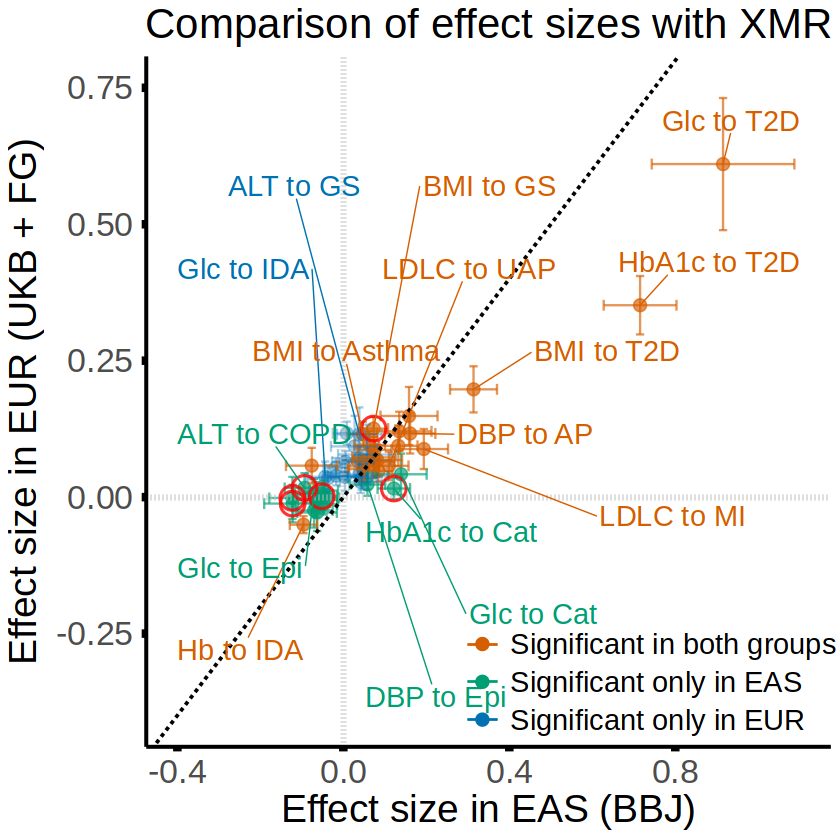

In [24]:
method_list = c('XMR', 'TEMR', 'MRAPSS',
                'Egger', 'Weighted-mode', 'IVW', 'Weighted-median', 
                'CAUSE', 'MRMix', 'MR-Robust', 'MR-PRESSO', 'IVW_fe', 'cML-MA', 'ConMix', 'dIVW', 'MR-Lasso')

method_name_list = method_list

i = 1
method = method_list[i]
method_name = method_name_list[i]


plot_scatter_BBJ_EUR(
  df_final,
  beta_bbj=paste0('beta_',method,'_', 'BBJ'), beta_eur=paste0('beta_MRAPSS_EUR'), beta_tpmi=paste0('beta_',method,'_', 'TPMI'),
  pval_bbj=paste0('beta.pvalue_',method,'_', 'BBJ'), pval_eur=paste0('beta.pvalue_MRAPSS_EUR'), pval_tpmi=paste0('beta.pvalue_',method,'_', 'TPMI'), 
  se_bbj=paste0('beta.se_',method,'_', 'BBJ'), se_eur=paste0('beta.se_MRAPSS_EUR'), se_tpmi=paste0('beta.se_',method,'_', 'TPMI'),
  method_name = "XMR",
  exp_ab_order=exp_ab_order, out_ab_order=out_ab_order,
  exp_name_to_abbr=exp_name_to_abbr, out_name_to_abbr=out_name_to_abbr,
  plot = TRUE,
  label_exclude = data.frame(exposure = c("4079",  "4079",  "30740", "30740", "21001"),
                             outcome  = c("250.2", "174.1", "496.21", "495",  "496.21")),
  label_include = data.frame(exposure = c("4079"),
                             outcome  = c("345.1"))

)


for(i in 2:length(method_list)){
    
    method = method_list[i]
    method_name = method_name_list[i]
    
   
    plot_scatter_BBJ_EUR(df_final,
                         beta_bbj=paste0('beta_',method,'_', 'BBJ'), beta_eur=paste0('beta_',method,'_EUR'), beta_tpmi=paste0('beta_',method,'_', 'TPMI'),
                         pval_bbj=paste0('beta.pvalue_',method,'_', 'BBJ'), pval_eur=paste0('beta.pvalue_',method,'_EUR'), pval_tpmi=paste0('beta.pvalue_',method,'_', 'TPMI'), 
                         se_bbj=paste0('beta.se_',method,'_', 'BBJ'), se_eur=paste0('beta.se_',method,'_EUR'), se_tpmi=paste0('beta.se_',method,'_', 'TPMI'),
                         method_name=method_name,
                         exp_ab_order=exp_ab_order, out_ab_order=out_ab_order,
                         exp_name_to_abbr=exp_name_to_abbr, out_name_to_abbr=out_name_to_abbr,
                         plot = FALSE)

    
    
}